# HW1 — Introduction and Learnability
**Statistical and Machine Learning — M2, Université de Haute-Alsace**

Goal: illustrate the difference between PAC and Agnostic PAC learning with an ERM over threshold classifiers, implemented with NumPy only.

In [70]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)  # fixed seed for reproducibility

## 0. Experimental parameters

For threshold classifiers in the realizable case, $\Pr(L(h) > \varepsilon) \le 2(1-\varepsilon)^m$, which gives the sample complexity $m \ge \ln(2/\delta)/\varepsilon$. We use it to choose ε and δ.

In [71]:
M_VALUES = [5, 10, 20, 50, 100, 200]

print("Bound 2(1-eps)^m")
for eps in [0.01, 0.05, 0.2]:
    print(f"eps = {eps:<5}", [round(min(1, 2 * (1 - eps) ** m), 4) for m in M_VALUES])

print("\nSample complexity for delta = 0.05:", {eps: round(float(np.log(2 / 0.05) / eps), 1) for eps in [0.01, 0.05, 0.2]})

Bound 2(1-eps)^m
eps = 0.01  [1, 1, 1, 1, 0.7321, 0.268]
eps = 0.05  [1, 1, 0.717, 0.1539, 0.0118, 0.0001]
eps = 0.2   [0.6554, 0.2147, 0.0231, 0.0, 0.0, 0.0]

Sample complexity for delta = 0.05: {0.01: 368.9, 0.05: 73.8, 0.2: 18.4}


- **ε = 0.05**: the bound goes from 1 to almost 0 inside our range of m. With ε = 0.01 it stays high until m = 200, with ε = 0.2 it is already close to 0 at m = 20.
- **δ = 0.05**: it gives $m \ge 74$, which we can compare with the experiments.
- **θ = 0.4**: not too close to 0 or 1, otherwise small samples often contain only one class.
- **η = 0.1 and 0.2**: we need η < 0.5, and two values let us compare noise levels.
- **1000 repetitions and a test set of 10 000 points**: standard deviations of about 0.016 and 0.005, small compared with ε.

In [72]:
THETA = 0.4               # target threshold
EPSILON = 0.05            # accuracy
DELTA = 0.05              # confidence
ETA_VALUES = [0.1, 0.2]   # noise rates
N_REPETITIONS = 1000
N_TEST = 10_000

## 1. Data Generation

Inputs are drawn uniformly in [0, 1] and labeled by the target threshold:
$$f_\theta(x) = \begin{cases} 1 & \text{if } x > \theta \\ 0 & \text{otherwise} \end{cases}$$
In the realizable setting $y = f_\theta(x)$. In the agnostic setting, each label is flipped with probability η.

In [73]:
def generate_data(m, theta=THETA, eta=0.0, rng=rng):
    """Draw m points uniformly in [0, 1] and label them with f_theta (labels flipped with probability eta)."""
    X = rng.uniform(0.0, 1.0, size=m)
    y = (X > theta).astype(int)
    if eta > 0:
        flip = rng.random(m) < eta
        y = np.where(flip, 1 - y, y)
    return X, y


train_sets = {m: generate_data(m) for m in M_VALUES}   # one realizable training set per m
for m, (X, y) in train_sets.items():
    print(f"m = {m:3d} | positives = {y.sum():3d} | negatives = {m - y.sum():3d} "
          f"| proportion of positives = {y.mean():.2f} (expected {1 - THETA:.2f})")

m =   5 | positives =   4 | negatives =   1 | proportion of positives = 0.80 (expected 0.60)
m =  10 | positives =   8 | negatives =   2 | proportion of positives = 0.80 (expected 0.60)
m =  20 | positives =  12 | negatives =   8 | proportion of positives = 0.60 (expected 0.60)
m =  50 | positives =  30 | negatives =  20 | proportion of positives = 0.60 (expected 0.60)
m = 100 | positives =  61 | negatives =  39 | proportion of positives = 0.61 (expected 0.60)
m = 200 | positives = 116 | negatives =  84 | proportion of positives = 0.58 (expected 0.60)


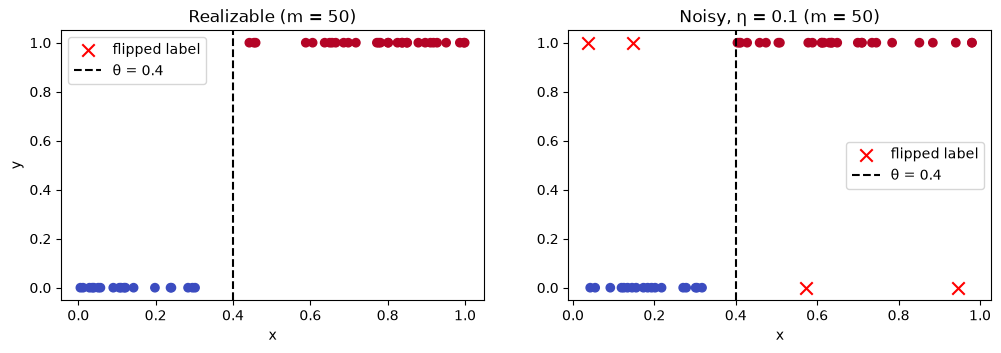

In [74]:
X_clean, y_clean = generate_data(50)
X_noisy, y_noisy = generate_data(50, eta=0.1)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, X, y, title in [(axes[0], X_clean, y_clean, "Realizable (m = 50)"),
                        (axes[1], X_noisy, y_noisy, "Noisy, η = 0.1 (m = 50)")]:
    flipped = y != (X > THETA)
    ax.scatter(X[~flipped], y[~flipped], c=y[~flipped], cmap="coolwarm")
    ax.scatter(X[flipped], y[flipped], c="red", marker="x", s=80, label="flipped label")
    ax.axvline(THETA, color="black", linestyle="--", label="θ = 0.4")
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.legend()
axes[0].set_ylabel("y")
plt.show()

Without noise, θ separates the two classes perfectly. With noise, some points (red crosses) are on the wrong side, so no threshold can classify the whole sample correctly.

## 2. Implementation of ERM

The hypothesis class is $H = \{h_t : t \in [0,1]\}$ with $h_t(x) = \mathbb{1}[x > t]$. ERM returns
$$\hat{t} \in \arg\min_{t} L_S(h_t), \qquad L_S(h_t) = \frac{1}{m}\sum_{i=1}^m \mathbb{1}[h_t(x_i) \neq y_i].$$
$L_S(h_t)$ only changes when $t$ crosses a training point, so it is enough to test one threshold per interval: we sort the points, add 0 and 1, and take the **midpoints** (m + 1 candidates). We keep the one with the smallest error (the smallest threshold in case of a tie).

In [75]:
def empirical_error(X, y, t):
    """Fraction of points misclassified by the threshold t."""
    return np.mean((X > t).astype(int) != y)


def erm_threshold(X, y):
    """Return the threshold with the smallest empirical error (t_hat) and this error."""
    bounds = np.concatenate(([0.0], np.sort(X), [1.0]))
    candidates = (bounds[:-1] + bounds[1:]) / 2                     # m + 1 midpoints
    errors = np.mean((X[None, :] > candidates[:, None]) != y[None, :], axis=1)
    best = np.argmin(errors)
    return candidates[best], errors[best]

## 3. Performance Evaluation

For each training set we compare the empirical error $L_S(h_{\hat{t}})$ with the true error
$$L_\mathcal{D}(h_{\hat{t}}) = \Pr_{x \sim \mathcal{D}}\big[h_{\hat{t}}(x) \neq y\big],$$
estimated on an independent test set of 10 000 points.

   m |  t_hat | empirical error | true error
   5 |  0.267 |          0.0000 |     0.1325
  10 |  0.407 |          0.0000 |     0.0066
  20 |  0.419 |          0.0000 |     0.0181
  50 |  0.397 |          0.0000 |     0.0027
 100 |  0.398 |          0.0000 |     0.0012
 200 |  0.405 |          0.0000 |     0.0054


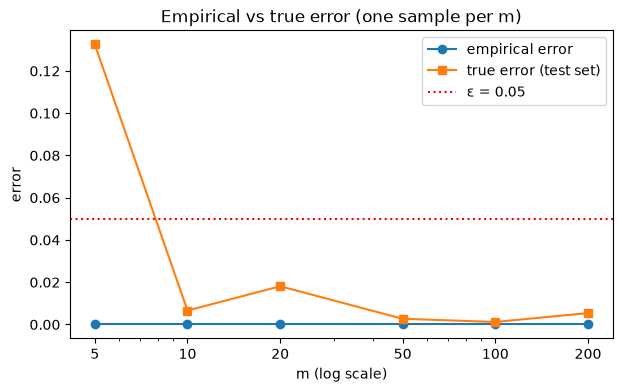

In [76]:
X_test, y_test = generate_data(N_TEST)

emp_errors, true_errors = [], []
print(f"{'m':>4} | {'t_hat':>6} | {'empirical error':>15} | {'true error':>10}")
for m, (X, y) in train_sets.items():
    t_hat, emp_err = erm_threshold(X, y)
    true_err = empirical_error(X_test, y_test, t_hat)
    emp_errors.append(emp_err)
    true_errors.append(true_err)
    print(f"{m:>4} | {t_hat:>6.3f} | {emp_err:>15.4f} | {true_err:>10.4f}")

plt.figure(figsize=(7, 4))
plt.plot(M_VALUES, emp_errors, "o-", label="empirical error")
plt.plot(M_VALUES, true_errors, "s-", label="true error (test set)")
plt.axhline(EPSILON, color="red", linestyle=":", label="ε = 0.05")
plt.xscale("log")
plt.xticks(M_VALUES, M_VALUES)
plt.xlabel("m (log scale)")
plt.ylabel("error")
plt.title("Empirical vs true error (one sample per m)")
plt.legend()
plt.show()

The empirical error is always 0, but the true error is not: for m = 5 it is about 0.13, above ε. It gets smaller when m increases, but not regularly because there is only one sample per m. This is why we repeat the experiment in Section 4.

## 4. Experimental Verification of PAC Learning

The class is PAC learnable if, for m large enough, $\Pr\big(L_\mathcal{D}(h) > \varepsilon\big) \le \delta$.
For each m we repeat 1000 times (new sample, ERM, true error) and estimate this probability by
$$\widehat{\Pr}(L(h) > \varepsilon) = \frac{1}{N}\sum_{r=1}^{N} \mathbb{1}\big[L(h^{(r)}) > \varepsilon\big].$$
Theory predicts that it stays below $2(1-\varepsilon)^m$ and goes below δ for $m \ge 74$.

m =   5 | Pr(L > eps) = 0.592 | bound = 1.000
m =  10 | Pr(L > eps) = 0.346 | bound = 1.000
m =  20 | Pr(L > eps) = 0.129 | bound = 0.717
m =  50 | Pr(L > eps) = 0.006 | bound = 0.154
m = 100 | Pr(L > eps) = 0.000 | bound = 0.012
m = 200 | Pr(L > eps) = 0.000 | bound = 0.000


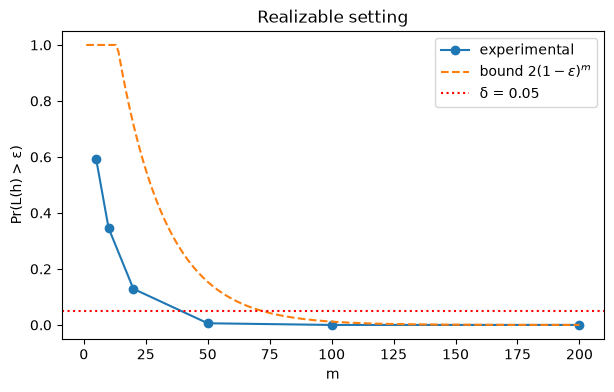

In [77]:
def run_experiment(m, eta=0.0, X_test=X_test, y_test=y_test):
    """Repeat ERM N_REPETITIONS times and return the empirical and true errors."""
    emp_errors, true_errors = [], []
    for _ in range(N_REPETITIONS):
        X, y = generate_data(m, eta=eta)
        t_hat, emp_err = erm_threshold(X, y)
        emp_errors.append(emp_err)
        true_errors.append(empirical_error(X_test, y_test, t_hat))
    return np.array(emp_errors), np.array(true_errors)


results = {m: run_experiment(m) for m in M_VALUES}
p_fail = [np.mean(results[m][1] > EPSILON) for m in M_VALUES]

for m, p in zip(M_VALUES, p_fail):
    print(f"m = {m:3d} | Pr(L > eps) = {p:.3f} | bound = {min(1, 2 * (1 - EPSILON) ** m):.3f}")

m_grid = np.arange(1, 201)
plt.figure(figsize=(7, 4))
plt.plot(M_VALUES, p_fail, "o-", label="experimental")
plt.plot(m_grid, np.minimum(1, 2 * (1 - EPSILON) ** m_grid), "--", label="bound $2(1-\\varepsilon)^m$")
plt.axhline(DELTA, color="red", linestyle=":", label="δ = 0.05")
plt.xlabel("m")
plt.ylabel("Pr(L(h) > ε)")
plt.title("Realizable setting")
plt.legend()
plt.show()

The probability of failure goes from 0.59 (m = 5) to 0.006 (m = 50) and 0 for m ≥ 100, so the class is PAC learnable. It always stays below the bound and goes below δ between m = 20 and 50, earlier than the theoretical m ≈ 74: the bound is pessimistic.

## 5. From PAC to Agnostic PAC

With noise, even the target threshold makes errors, so the best error in the class is
$$\min_{h \in H} L_\mathcal{D}(h) = L_\mathcal{D}(h_\theta) = \eta.$$
The agnostic PAC criterion therefore looks at the excess risk:
$$\Pr\Big(L_\mathcal{D}(h) - \min_{h \in H} L_\mathcal{D}(h) > \varepsilon\Big) \le \delta.$$
We repeat the experiments of Section 4 with η = 0.1 and 0.2, using a noisy test set.

In [78]:
results_noisy = {}
for eta in ETA_VALUES:
    X_te, y_te = generate_data(N_TEST, eta=eta)
    best_error = empirical_error(X_te, y_te, THETA)            # error of theta on this test set (about eta)
    results_noisy[eta] = (best_error, {m: run_experiment(m, eta, X_te, y_te) for m in M_VALUES})

for eta, (best_error, res) in results_noisy.items():
    print(f"\neta = {eta} (error of theta: {best_error:.4f})")
    print(f"{'m':>4} | {'mean emp':>8} | {'Pr(emp=0)':>9} | {'mean true':>9} | {'Pr(L>eps)':>9} | {'Pr(L-eta>eps)':>13}")
    for m in M_VALUES:
        emp, true = res[m]
        print(f"{m:>4} | {emp.mean():>8.4f} | {np.mean(emp == 0):>9.3f} | {true.mean():>9.4f} | "
              f"{np.mean(true > EPSILON):>9.3f} | {np.mean(true - best_error > EPSILON):>13.3f}")


eta = 0.1 (error of theta: 0.0999)
   m | mean emp | Pr(emp=0) | mean true | Pr(L>eps) | Pr(L-eta>eps)
   5 |   0.0576 |     0.738 |    0.1989 |     1.000 |         0.636
  10 |   0.0777 |     0.426 |    0.1742 |     1.000 |         0.505
  20 |   0.0915 |     0.131 |    0.1413 |     1.000 |         0.276
  50 |   0.0941 |     0.008 |    0.1181 |     1.000 |         0.074
 100 |   0.0975 |     0.000 |    0.1093 |     1.000 |         0.010
 200 |   0.0977 |     0.000 |    0.1048 |     1.000 |         0.001

eta = 0.2 (error of theta: 0.1995)
   m | mean emp | Pr(emp=0) | mean true | Pr(L>eps) | Pr(L-eta>eps)
   5 |   0.1122 |     0.519 |    0.3063 |     1.000 |         0.664
  10 |   0.1373 |     0.195 |    0.2804 |     1.000 |         0.537
  20 |   0.1673 |     0.020 |    0.2539 |     1.000 |         0.375
  50 |   0.1907 |     0.000 |    0.2234 |     1.000 |         0.147
 100 |   0.1947 |     0.000 |    0.2121 |     1.000 |         0.040
 200 |   0.1969 |     0.000 |    0.2059 |   

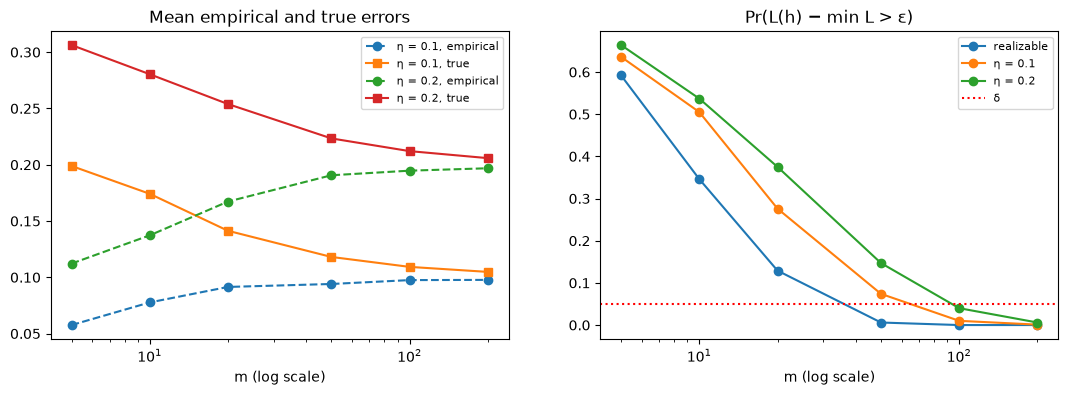

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[1].plot(M_VALUES, p_fail, "o-", label="realizable")
for eta, (best_error, res) in results_noisy.items():
    axes[0].plot(M_VALUES, [res[m][0].mean() for m in M_VALUES], "o--", label=f"η = {eta}, empirical")
    axes[0].plot(M_VALUES, [res[m][1].mean() for m in M_VALUES], "s-", label=f"η = {eta}, true")
    axes[1].plot(M_VALUES, [np.mean(res[m][1] - best_error > EPSILON) for m in M_VALUES], "o-", label=f"η = {eta}")
axes[1].axhline(DELTA, color="red", linestyle=":", label="δ")
axes[0].set_title("Mean empirical and true errors")
axes[1].set_title("Pr(L(h) − min L > ε)")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("m (log scale)")
    ax.legend(fontsize=8)
plt.show()

**1. Can the empirical error still reach zero?** Only for very small samples (about 74% of the time for m = 5 with η = 0.1), and never for m ≥ 100. For large m it gets close to η, because about η·m labels are wrong.

**2. Does more data still improve generalization?** Yes, but not in the PAC sense: $\Pr(L(h) > \varepsilon) = 1$ for every m, because the error can never go below η. What improves is the excess risk $L(h) - \eta$, which goes to 0, more slowly than without noise and more slowly for η = 0.2 than for η = 0.1.

**3. Link with PAC / Agnostic PAC.** In the PAC setting the target is in the class, so the true error itself goes to 0. In the agnostic setting there is no perfect hypothesis, so we only ask to be close to the best one in the class ($\min_H L = \eta$). This is what we observe.

## Conclusion

We implemented ERM for threshold classifiers with NumPy only. Without noise, the empirical error is always 0 and the probability of a bad threshold decreases quickly with m, as predicted by PAC theory. With noise, the empirical error cannot reach 0 and the true error stays above η, but the excess risk still goes to 0: the class is still learnable in the agnostic sense, just more slowly.